# BEKANTOR Demand Intelligence — Forecasting V2

## tl;dr

Esta es la **corrida completa**: 20 trials de Optuna,
máximo 1500 árboles LightGBM y CatBoost congelado
en 915 iteraciones después de calibrarlo sólo
con los cuatro folds de tuning. Los dos folds externos terminan el
31/07/2017; **agosto no fue usado ni evaluado**.

**LightGBM optimizado** obtuvo el menor RMSLE externo medio:
**0.389282**, frente a **0.390548**
del LightGBM original. La diferencia es **0.001267**
(0.32% relativa) y favorece al optimizado en ambos folds,
pero sigue siendo pequeña y se basa en sólo dos ventanas externas.

CatBoost obtuvo **0.401935** y TSB
**0.479565**. El simulador de inventario fue recalculado con
stock inicial, stock de seguridad, demanda y costos comunes para todos los
modelos, de modo que las diferencias reflejen sus decisiones de forecast.

## Contexto y métodos

Cada fold deriva su universo desde su cutoff y pronostica 15 días de forma
recursiva. Optuna observa exclusivamente los folds 1–4; los folds 5–6 se
reservan para comparación externa. El número de árboles LightGBM se
calibra en una ventana interna y la función objetivo usa el horizonte
recursivo completo.

### Supuestos clave

- La comparación externa exige las mismas claves fecha–tienda–familia para todos los modelos.
- El escenario promocional parcial confirma 7 días y estima el resto con historia anterior al cutoff.
- El caso de inventario usa una política comercial común: stock inicial igual al 25% del forecast del baseline estacional; stock de seguridad común al 95%, estimado con sus errores del fold externo anterior; lead time de 3 días; costos idénticos.
- Las ventas observadas son una demanda de comparación común, no evidencia de demanda irrestricta ni de faltantes históricos.

In [1]:
from pathlib import Path
import json
import platform

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
OUT = ROOT / "outputs" / "forecasting_v2_full"
plt.style.use("seaborn-v0_8-whitegrid")
MODEL_COLORS = {
    "LightGBM optimized": "#2563eb",
    "LightGBM original": "#d97706",
    "CatBoost": "#7c3aed",
    "Seasonal baseline": "#64748b",
    "TSB": "#0f766e",
}
pd.set_option("display.max_columns", 40)

manifest = json.loads((OUT / "run_manifest.json").read_text(encoding="utf-8"))
best = json.loads((OUT / "best_lightgbm.json").read_text(encoding="utf-8"))
cat_budget = json.loads((OUT / "catboost_iterations.json").read_text(encoding="utf-8"))
assert manifest["protocol"] == "full"
assert manifest["august_evaluated"] is False
print("Python:", platform.python_version())
print("Duración total (h):", round(manifest["elapsed_seconds"] / 3600, 2))
print("LightGBM seleccionado (árboles):", best["selected_n_estimators"])
print("CatBoost seleccionado (iteraciones):", cat_budget["selected_iterations"])

Python: 3.13.15
Duración total (h): 9.32
LightGBM seleccionado (árboles): 592
CatBoost seleccionado (iteraciones): 915


## Datos y contrato temporal

In [2]:
folds = pd.read_csv(OUT / "folds.csv", parse_dates=["train_end", "validation_start", "validation_end"])
assert len(folds) == 6
assert folds["role"].tolist() == ["tuning"] * 4 + ["development_evaluation"] * 2
assert folds["validation_end"].max() < pd.Timestamp("2017-08-01")
display(folds)

,fold,train_end,validation_start,validation_end,role
0,1,2017-05-02,2017-05-03,2017-05-17,tuning
1,2,2017-05-17,2017-05-18,2017-06-01,tuning
2,3,2017-06-01,2017-06-02,2017-06-16,tuning
3,4,2017-06-16,2017-06-17,2017-07-01,tuning
4,5,2017-07-01,2017-07-02,2017-07-16,development_evaluation
5,6,2017-07-16,2017-07-17,2017-07-31,development_evaluation


## Resultados

### Optimización LightGBM, CatBoost y TSB

Estados Optuna: {'COMPLETE': 17, 'PRUNED': 3}


,max_depth,num_leaves,learning_rate,min_child_samples,reg_lambda,objective_recursive_rmsle,selected_n_estimators,tuning_fold_best_iterations,tuning_fold_rmsle,near_estimator_cap_folds,estimator_cap_is_binding
0,10,252,0.042074,41,9.611896,0.403415,592,"[184, 759, 1227, 426]","[0.43852777256224523, 0.3952642419772963, 0.39...",0,False


,selected_iterations,fold_best_iterations,max_iterations,source,protocol_version,data_signature,folds
0,915,"[654, 1000, 1000, 831]",1000,tuning_inner_early_stopping_median,forecasting-v2.1,597ba3759c8be1cb,"[1, 2, 3, 4]"


,alpha,beta,RMSLE_mean
0,0.2,0.1,0.509417
1,0.2,0.2,0.509621
2,0.2,0.3,0.510870
3,0.1,0.2,0.510967
4,0.1,0.3,0.511898
5,0.1,0.1,0.512240
6,0.3,0.1,0.512931
7,0.3,0.2,0.513602
8,0.3,0.3,0.514925


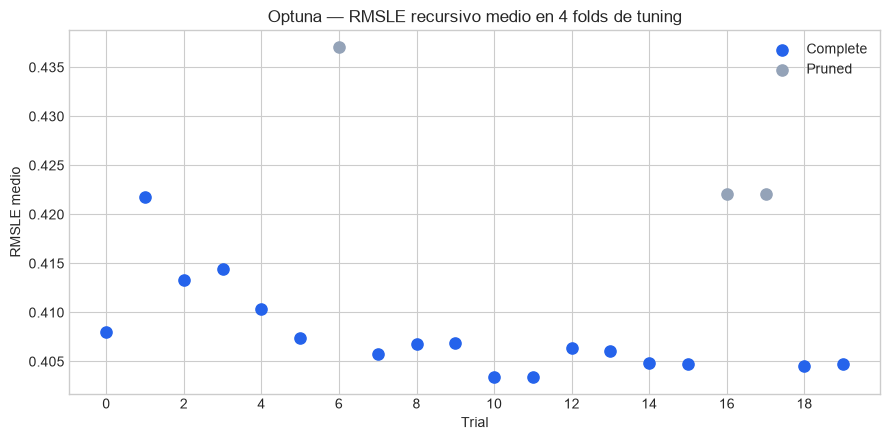

In [3]:
trials = pd.read_csv(OUT / "optuna_trials.csv")
tsb_search = pd.read_csv(OUT / "tsb_parameter_search.csv")
print("Estados Optuna:", trials["state"].value_counts().to_dict())
display(pd.DataFrame([best]).round(6))
display(pd.DataFrame([cat_budget]))
display(tsb_search.round(6))

fig, ax = plt.subplots(figsize=(9, 4.5))
state_colors = {"COMPLETE": "#2563eb", "PRUNED": "#94a3b8"}
for state, group in trials.groupby("state"):
    ax.scatter(group["number"], group["value"], s=65,
               color=state_colors[state], label=state.title())
ax.set(title="Optuna — RMSLE recursivo medio en 4 folds de tuning",
       xlabel="Trial", ylabel="RMSLE medio")
ax.set_xticks(range(0, len(trials), 2))
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

CatBoost llegó al máximo de 1000 iteraciones en
2 de 4 ventanas internas. Su resultado externo sigue siendo
una medición válida del modelo congelado en 915
iteraciones, pero no demuestra que ése sea el presupuesto óptimo de CatBoost.

### Comparación consolidada en desarrollo externo

,model,folds,RMSLE_mean,RMSLE_std,MAE_mean,WAPE_pct_mean,Bias_pct_mean
1,LightGBM optimized,2,0.389282,0.016276,54.409125,10.955680,-2.763419
2,LightGBM original,2,0.390548,0.016456,55.170122,11.104623,-3.060780
0,CatBoost,2,0.401935,0.015405,63.407271,12.755792,-3.292287
3,Seasonal baseline,2,0.439960,0.017886,66.143295,13.293685,0.446904
4,TSB,2,0.479565,0.015190,115.190661,23.143631,1.477774


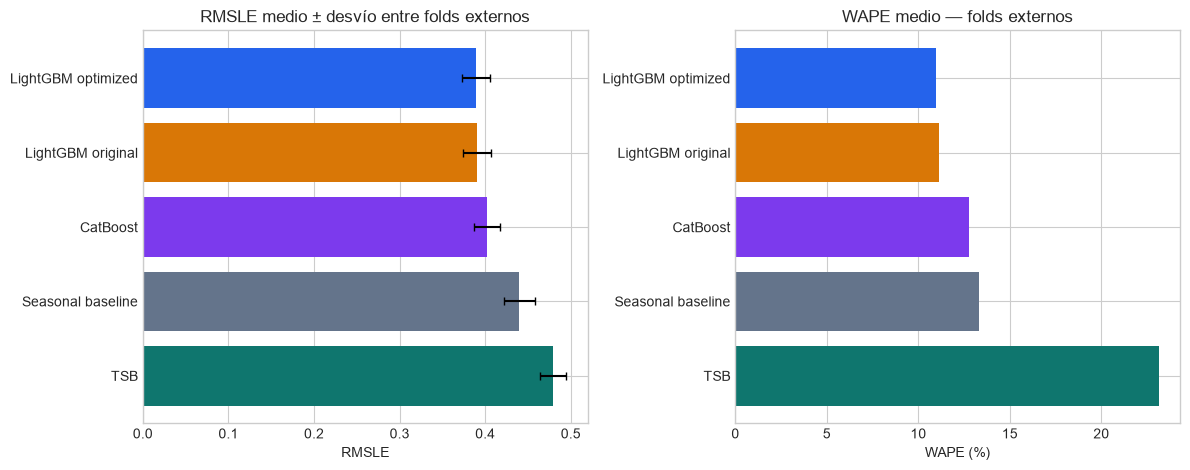

In [4]:
comparison = pd.read_csv(OUT / "model_comparison.csv").sort_values("RMSLE_mean")
display(comparison.round(6))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
colors = [MODEL_COLORS[name] for name in comparison["model"]]
axes[0].barh(comparison["model"], comparison["RMSLE_mean"],
             xerr=comparison["RMSLE_std"], color=colors, capsize=3)
axes[0].invert_yaxis()
axes[0].set(title="RMSLE medio ± desvío entre folds externos",
            xlabel="RMSLE", ylabel="")
axes[0].set_xlim(left=0)
axes[1].barh(comparison["model"], comparison["WAPE_pct_mean"], color=colors)
axes[1].invert_yaxis()
axes[1].set(title="WAPE medio — folds externos", xlabel="WAPE (%)", ylabel="")
axes[1].set_xlim(left=0)
plt.tight_layout()
plt.show()

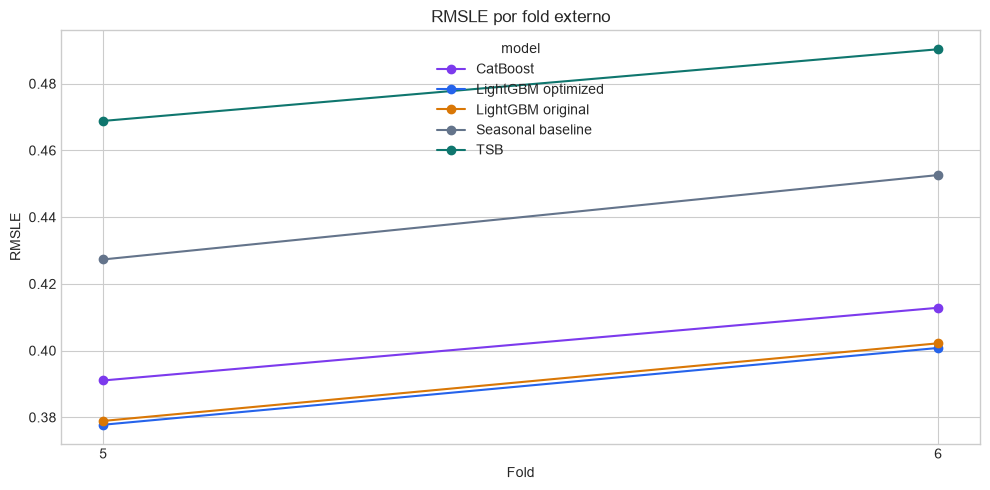

,fold,role,model,RMSLE,MAE,MSE_signed,WAPE_pct,Bias_pct,Overprediction,Underprediction
8,5,development_evaluation,Seasonal baseline,0.427312,67.632701,-2.912112,13.228557,-0.569592,8.387788e+05,9.142608e+05
9,5,development_evaluation,LightGBM original,0.378913,53.444888,-10.256984,10.453504,-2.006206,5.597152e+05,8.255763e+05
10,5,development_evaluation,LightGBM optimized,0.377773,51.940342,-7.822219,10.159224,-1.529980,5.717709e+05,7.745228e+05
11,5,development_evaluation,CatBoost,0.391042,62.658038,-10.684405,12.255542,-2.089807,6.735783e+05,9.505181e+05
12,5,development_evaluation,TSB,0.468824,119.189466,-13.228496,23.312756,-2.587416,1.373254e+06,1.716137e+06
13,6,development_evaluation,Seasonal baseline,0.452607,64.653889,7.082558,13.358812,1.463401,9.302424e+05,7.465562e+05
14,6,development_evaluation,LightGBM original,0.402184,56.895356,-19.917462,11.755741,-4.115354,4.795108e+05,9.960702e+05
15,6,development_evaluation,LightGBM optimized,0.400791,56.877908,-19.343969,11.752136,-3.996858,4.867214e+05,9.884072e+05
16,6,development_evaluation,CatBoost,0.412828,64.156504,-21.753745,13.256042,-4.494767,5.498578e+05,1.114041e+06
17,6,development_evaluation,TSB,0.490306,111.191856,26.826797,22.974505,5.542963,1.789757e+06,1.094004e+06


In [5]:
fold_metrics = pd.read_csv(OUT / "fold_metrics.csv")
heldout = fold_metrics.loc[fold_metrics["role"].eq("development_evaluation")]
pivot = heldout.pivot(index="fold", columns="model", values="RMSLE")
ax = pivot.plot(marker="o", figsize=(10, 5),
                color=[MODEL_COLORS[name] for name in pivot.columns])
ax.set(title="RMSLE por fold externo", xlabel="Fold", ylabel="RMSLE")
ax.set_xticks([5, 6])
plt.tight_layout()
plt.show()
display(heldout.round(6))

### Población común y comportamiento por horizonte

,fold,model,observations,horizon_days,series
0,5,CatBoost,25920,15,1728
1,5,LightGBM optimized,25920,15,1728
2,5,LightGBM original,25920,15,1728
3,5,Seasonal baseline,25920,15,1728
4,5,TSB,25920,15,1728
5,6,CatBoost,25935,15,1729
6,6,LightGBM optimized,25935,15,1729
7,6,LightGBM original,25935,15,1729
8,6,Seasonal baseline,25935,15,1729
9,6,TSB,25935,15,1729


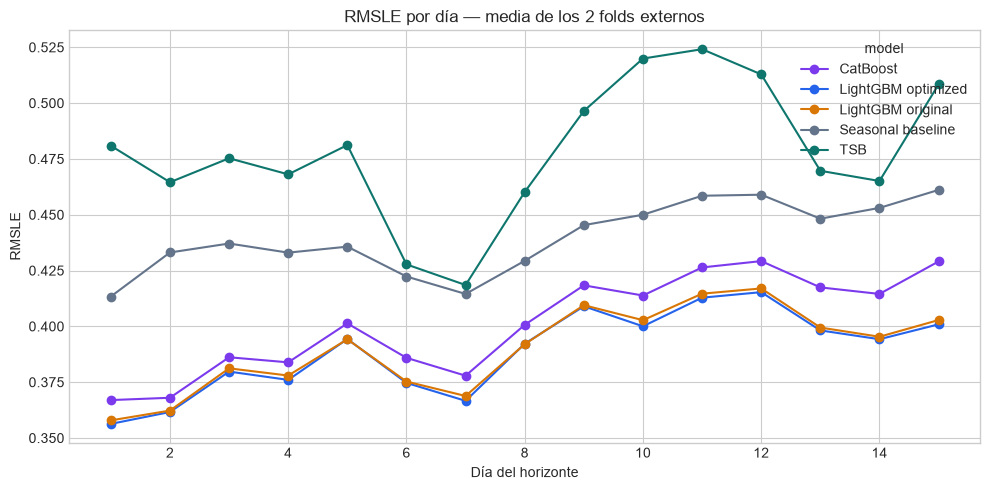

In [6]:
segments = pd.read_csv(OUT / "segment_diagnostics.csv")
horizon = segments.loc[segments["dimension"].eq("horizon")].copy()
horizon["segment"] = horizon["segment"].astype(int)
coverage = horizon.groupby(["fold", "model"], as_index=False).agg(
    observations=("n_obs", "sum"), horizon_days=("segment", "nunique"),
    series=("n_series", "max"),
)
assert coverage.groupby("fold")["observations"].nunique().eq(1).all()
assert coverage["horizon_days"].eq(15).all()
display(coverage)

horizon_mean = horizon.groupby(["segment", "model"], as_index=False)["RMSLE"].mean()
horizon_pivot = horizon_mean.pivot(index="segment", columns="model", values="RMSLE")
ax = horizon_pivot.plot(marker="o", figsize=(10, 5),
                        color=[MODEL_COLORS[name] for name in horizon_pivot.columns])
ax.set(title="RMSLE por día — media de los 2 folds externos",
       xlabel="Día del horizonte", ylabel="RMSLE")
plt.tight_layout()
plt.show()

### Familias y tipos ADI/CV²

,fold,model,dimension,segment,RMSLE,MAE,WAPE_pct,Bias_pct,n_obs,n_series
13,5,Seasonal baseline,family,GROCERY II,0.6170,11.0398,34.1855,-7.5226,810,54
21,5,Seasonal baseline,family,LINGERIE,0.6662,3.4691,51.3899,2.8072,810,54
88,5,Seasonal baseline,demand_type,Intermitente,0.4461,14.9340,14.1662,-7.7982,6090,406
89,5,Seasonal baseline,demand_type,Lumpy,0.5646,5.2511,38.1118,3.9575,4095,273
124,5,LightGBM original,family,GROCERY II,0.5833,10.7434,33.2677,-20.9915,810,54
132,5,LightGBM original,family,LINGERIE,0.5990,3.0210,44.7519,-16.9146,810,54
199,5,LightGBM original,demand_type,Intermitente,0.3967,13.1677,12.4908,-2.1754,6090,406
200,5,LightGBM original,demand_type,Lumpy,0.4917,4.2887,31.1271,-7.3611,4095,273
235,5,LightGBM optimized,family,GROCERY II,0.5841,10.8135,33.4848,-21.9817,810,54
243,5,LightGBM optimized,family,LINGERIE,0.5989,3.0235,44.7889,-15.8502,810,54


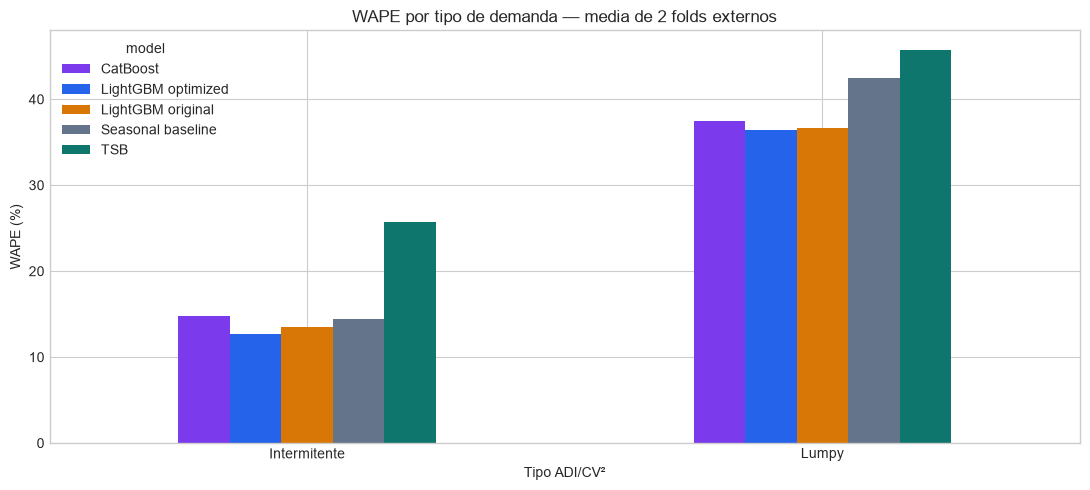

In [7]:
focus = segments.loc[
    ((segments["dimension"] == "family") & segments["segment"].isin(["LINGERIE", "GROCERY II"]))
    | ((segments["dimension"] == "demand_type") & segments["segment"].isin(["Intermitente", "Lumpy"]))
]
display(focus[["fold", "model", "dimension", "segment", "RMSLE", "MAE",
               "WAPE_pct", "Bias_pct", "n_obs", "n_series"]].round(4))

demand_type = focus.loc[focus["dimension"].eq("demand_type")].groupby(
    ["segment", "model"], as_index=False
)["WAPE_pct"].mean()
chart = demand_type.pivot(index="segment", columns="model", values="WAPE_pct")
chart.plot(kind="bar", figsize=(11, 5),
           color=[MODEL_COLORS[name] for name in chart.columns])
plt.title("WAPE por tipo de demanda — media de 2 folds externos")
plt.xlabel("Tipo ADI/CV²")
plt.ylabel("WAPE (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Escenarios de promociones

,scenario,confirmed_days,forecast_total,RMSLE,MAE,MSE_signed,WAPE_pct,Bias_pct,Overprediction,Underprediction
0,full,15,1.205032e+07,0.4008,56.8779,-19.3440,11.7521,-3.9969,486721.3547,9.884072e+05
1,partial,7,1.193934e+07,0.4280,57.7507,-23.6231,11.9325,-4.8810,442549.6025,1.055214e+06
2,none,0,1.179207e+07,0.4618,59.1711,-29.3014,12.2260,-6.0543,387334.6253,1.147267e+06


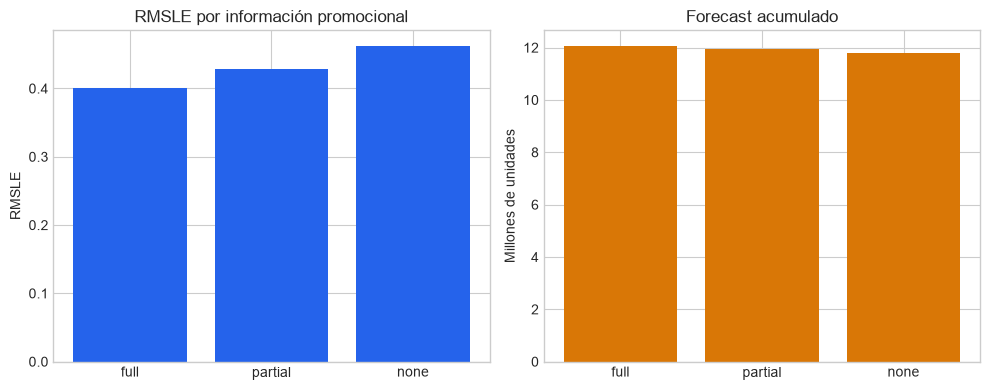

In [8]:
promotions = pd.read_csv(OUT / "promotion_scenarios.csv")
display(promotions.round(4))
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].bar(promotions["scenario"], promotions["RMSLE"], color="#2563eb")
axes[0].set(title="RMSLE por información promocional", ylabel="RMSLE")
axes[0].set_ylim(bottom=0)
axes[1].bar(promotions["scenario"], promotions["forecast_total"] / 1e6,
            color="#d97706")
axes[1].set(title="Forecast acumulado", ylabel="Millones de unidades")
axes[1].set_ylim(bottom=0)
plt.tight_layout()
plt.show()

La sensibilidad promocional no estima causalidad. Mide el deterioro del
mismo sistema cuando promociones no confirmadas se sustituyen por tasas
históricas calculadas únicamente hasta el cutoff.

### Simulación de inventario con política común

,model,initial_stock_assumption,safety_stock,service_level,lead_time_days,unit_cost,holding_cost_per_unit,shortage_penalty_per_unit,simulated_demand,forecast_demand,recommended_replenishment,ending_inventory,potential_shortage,simulated_total_cost
0,Seasonal baseline,7379.79,445.8,0.95,3,1.0,0.02,2.0,27794.44,29519.16,22585.17,2170.52,0.0,25527.20
1,LightGBM original,7379.79,445.8,0.95,3,1.0,0.02,2.0,27794.44,30390.58,23456.59,3041.94,0.0,26607.76
2,LightGBM optimized,7379.79,445.8,0.95,3,1.0,0.02,2.0,27794.44,29424.29,22490.30,2075.65,0.0,25409.56
3,CatBoost,7379.79,445.8,0.95,3,1.0,0.02,2.0,27794.44,29727.53,22793.54,2378.89,0.0,25785.58
4,TSB,7379.79,445.8,0.95,3,1.0,0.02,2.0,27794.44,29919.12,22985.14,2570.48,0.0,26023.15


,model,scenario,demand_multiplier,simulated_demand,potential_shortage,ending_inventory,simulated_total_cost
0,Seasonal baseline,high_demand,1.15,31963.61,1998.65,0.00,28949.21
1,Seasonal baseline,observed_base,1.00,27794.44,0.00,2170.52,25527.20
2,Seasonal baseline,low_demand,0.85,23625.28,0.00,6339.69,26231.05
3,LightGBM original,high_demand,1.15,31963.61,1127.23,0.00,28269.50
4,LightGBM original,observed_base,1.00,27794.44,0.00,3041.94,26607.76
5,LightGBM original,low_demand,0.85,23625.28,0.00,7211.11,27311.61
6,LightGBM optimized,high_demand,1.15,31963.61,2093.52,0.00,29023.21
7,LightGBM optimized,observed_base,1.00,27794.44,0.00,2075.65,25409.56
8,LightGBM optimized,low_demand,0.85,23625.28,0.00,6244.81,26113.41
9,CatBoost,high_demand,1.15,31963.61,1790.27,0.00,28786.68


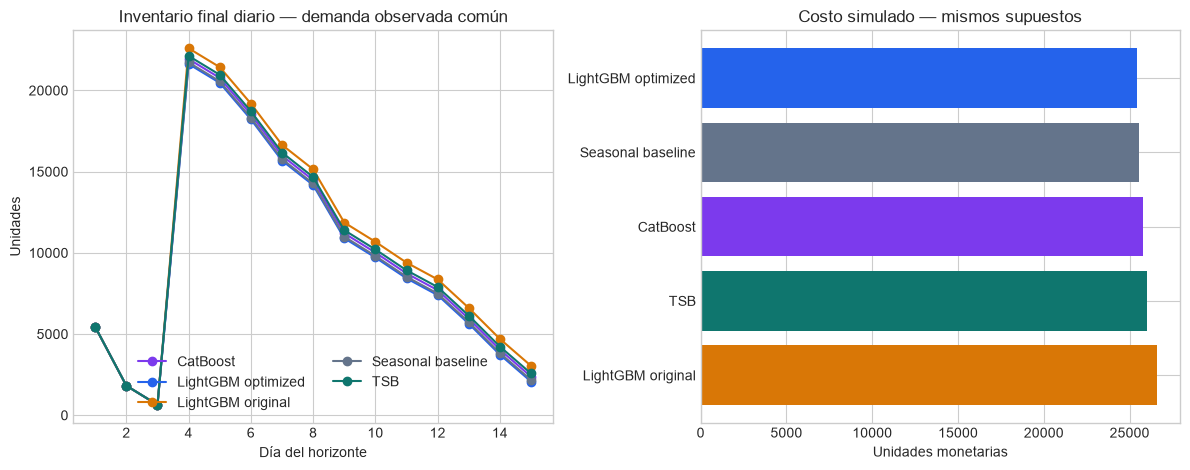

In [9]:
inventory = pd.read_csv(OUT / "inventory_example_summary.csv")
trajectory = pd.read_csv(OUT / "inventory_example_trajectory.csv")
sensitivity = pd.read_csv(OUT / "inventory_sensitivity.csv")
common = ["initial_stock_assumption", "safety_stock", "service_level",
          "lead_time_days", "unit_cost", "holding_cost_per_unit",
          "shortage_penalty_per_unit", "simulated_demand"]
assert all(inventory[column].nunique() == 1 for column in common)
display(inventory[["model", *common, "forecast_demand",
                   "recommended_replenishment", "ending_inventory",
                   "potential_shortage", "simulated_total_cost"]].round(2))
display(sensitivity[["model", "scenario", "demand_multiplier",
                     "simulated_demand", "potential_shortage",
                     "ending_inventory", "simulated_total_cost"]].round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for model, group in trajectory.groupby("model"):
    axes[0].plot(group["horizon_day"], group["ending_inventory"],
                 marker="o", label=model, color=MODEL_COLORS[model])
axes[0].set(title="Inventario final diario — demanda observada común",
            xlabel="Día del horizonte", ylabel="Unidades")
axes[0].legend(ncol=2, frameon=False)
order = inventory.sort_values("simulated_total_cost")
axes[1].barh(order["model"], order["simulated_total_cost"],
             color=[MODEL_COLORS[name] for name in order["model"]])
axes[1].invert_yaxis()
axes[1].set(title="Costo simulado — mismos supuestos",
            xlabel="Unidades monetarias", ylabel="")
axes[1].set_xlim(left=0)
plt.tight_layout()
plt.show()

## Takeaways

1. LightGBM optimizado mejora al original en los dos folds externos y
   reduce el RMSLE medio de 0.390548 a
   0.389282; la mejora relativa es 0.32%.
2. La ventaja es consistente pero pequeña. Dos folds externos no permiten
   afirmar significancia estadística ni garantizan superioridad futura.
3. CatBoost y TSB no superan a ambos LightGBM globalmente. CatBoost debe
   interpretarse con la salvedad de que 2/4 calibraciones internas tocaron
   el máximo de 1.000 iteraciones.
4. Menor confirmación promocional empeora RMSLE y reduce el forecast total;
   este resultado es sensibilidad predictiva, no efecto causal.
5. Con inventario, demanda, lead time, servicio y costos comunes, LightGBM
   optimizado produce el menor costo del caso demostrativo. Sigue siendo
   un escenario hipotético, no una medición de inventario real.

## Limitaciones

- Sólo dos folds externos comparan los cinco modelos costosos.
- Agosto no fue evaluado ni utilizado para seleccionar modelos.
- Las ventas observadas pueden estar censuradas por faltantes desconocidos.
- La política de inventario usa un baseline común porque Favorita no aporta stock histórico.
- Los escenarios ±15% son estrés operativo, no intervalos de confianza.